In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
import warnings
warnings.simplefilter("ignore", UserWarning)

In [3]:
import torch
import os
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
import numpy as np
import torch.nn.functional as F

import torch.nn as nn
from torch.utils.data import Subset, Dataset
from datasets import load_dataset

/home/nicole/miniconda3/envs/data-valuation-env/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
sys.path.insert(0, '.')
sys.path.append("..")
sys.path.append("../src")

from plot_utils import (
    plot_loss_acc,
    plot_train_val_loss_acc_separately,
    plot_loss_acc_difference,
    plot_var_acc_legends,
    plot_similar_indices
)

from utils import (
    top_last_influences,
    random_p_data,
    concat_ckpt_metrics,
    create_influences_dict,
    create_inf_int_distances,
    create_inter_entropies,
    create_inner_entropies,
    calc_pairwise_euclideans,
    calc_dist_inf_to_others,
    calc_volumes,
    pairwise_similarity,
    top_inf_indices,
    tsne_all_dataset,
    plt_decision_boundary,
)

from src.utils import load_checkpoint

In [5]:
dir_data="../data/"
dir_tensors = os.path.join("../influences/sst2", "sst2_put_time_here")
dir_ckpt = "../checkpoint/TextCNN"
dir_subset = os.path.join(dir_data,"subset_indices")
num_epochs = 100
ckpt_min = 1
ckpt_max = 100
p = 0.05
checkpoint_labels =  list([3, 6, 10, 13, 16, 20, 25, 40, 60, 80, 100])
epochs_range = range(1, num_epochs + 1)

In [6]:
class SST2EmbedDataset(Dataset):
    def __init__(self, embeddings, labels):
        self.embeddings = embeddings
        self.labels = labels

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        embedding = torch.tensor(self.embeddings[idx])
        label = torch.tensor(self.labels[idx])
        return embedding, label

In [7]:
sst2_dataset = load_dataset("SetFit/sst2")
subset_indices = torch.load(f"{dir_subset}/sst2_embed_train_subset_indices.pt")
EMBEDDING_TRAIN_SST2 = "../data/sst-2/embedding_train.pt"
sst2_train_embeddings = torch.load(EMBEDDING_TRAIN_SST2)
sst2_embed_train_dataset = SST2EmbedDataset(sst2_train_embeddings, sst2_dataset['train']['label'])
sst2_embed_train_subset = Subset(sst2_embed_train_dataset, subset_indices)


Repo card metadata block was not found. Setting CardData to empty.


In [8]:
# save_objs_dict = torch.load(f"{dir_tensors}/accuracies_and_losses.pt", weights_only=False)
save_objs_dict = torch.load("/home/nicole/Workspace/data_valuation/influences/sst2/sst2_2025-03-30_01-24-15/accuracies_and_losses.pt", weights_only=False)

train_losses = save_objs_dict["model_eval_obj"].train_losses
validation_losses = save_objs_dict["model_eval_obj"].validation_losses
accuracies = save_objs_dict["model_eval_obj"].accuracies

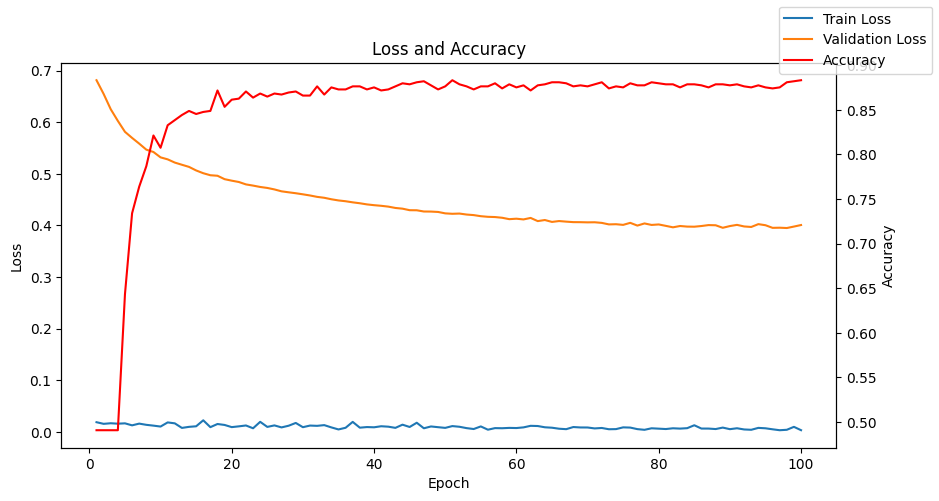

In [9]:
plot_loss_acc(epochs_range, train_losses, validation_losses, accuracies)

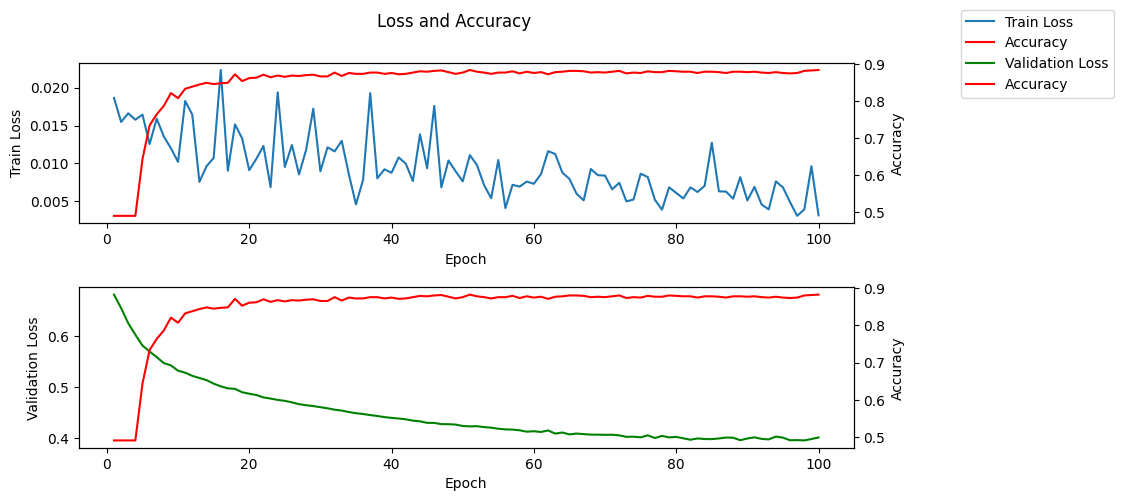

In [10]:
plot_train_val_loss_acc_separately(epochs_range, train_losses, validation_losses, accuracies)

# Influences

In [11]:
x_vals =  list(range(1, num_epochs+1))
num_data = len(sst2_embed_train_subset)
checkpoints_filepaths = [os.path.join(dir_ckpt, f"TextCNN_epoch_{epoch}_{epoch/num_epochs}.pth") for epoch in checkpoint_labels]

sst2_influences_if = save_objs_dict["influences_if"]
# sst2_influences_tracin = save_objs_dict["influences_tracin"]

scoring_methods = ["if"]
influences_methods = [sst2_influences_if]

validate_dict, rand_dict = create_influences_dict(save_objs_dict, checkpoint_labels, scoring_methods)

In [12]:
embeds_dict =  {}
for i in range(len(scoring_methods)):
    the_random_embeds = random_p_data(influences_methods[i], sst2_embed_train_subset, num_data, p) 
    the_random_embeds_large = random_p_data(influences_methods[i], sst2_embed_train_subset, num_data, p*10)
    the_last_ckpts_embeds = top_last_influences(influences_methods[i], sst2_embed_train_subset, int(p*num_data), False) 
    the_top_ckpts_embeds = top_last_influences(influences_methods[i], sst2_embed_train_subset, int(num_data*p))
    
    embeds_dict[scoring_methods[i]] = {
        "random": the_random_embeds, 
        "random_large": the_random_embeds_large, 
        "last": the_last_ckpts_embeds, 
        "top": the_top_ckpts_embeds}

In [13]:
len(the_random_embeds[0][0][0])

78

In [14]:
len(the_top_ckpts_embeds[0][0][0])

78

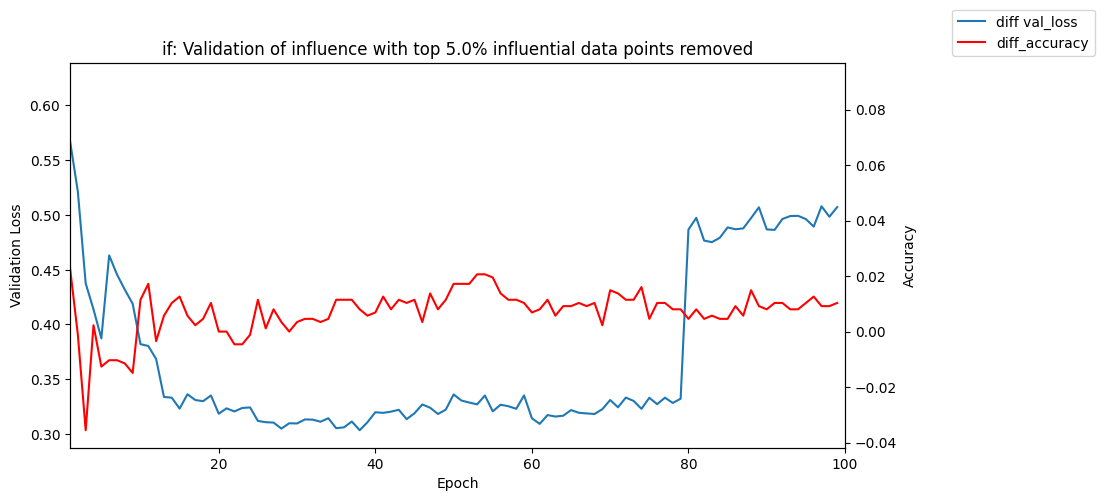

In [15]:
for scoring_method in scoring_methods:
    diff_val_loss = concat_ckpt_metrics(validate_dict[f"validate_validation_losses_{scoring_method}"], checkpoint_labels) - concat_ckpt_metrics(rand_dict[f"rand_validate_train_losses_{scoring_method}"], checkpoint_labels) # suppose positive
    diff_accuracy = concat_ckpt_metrics(rand_dict[f"rand_validate_accuracies_{scoring_method}"], checkpoint_labels) - concat_ckpt_metrics(validate_dict[f"validate_accuracies_{scoring_method}"], checkpoint_labels) # suppose positive
    plot_loss_acc_difference(diff_val_loss, diff_accuracy, scoring_method=scoring_method, p=p)

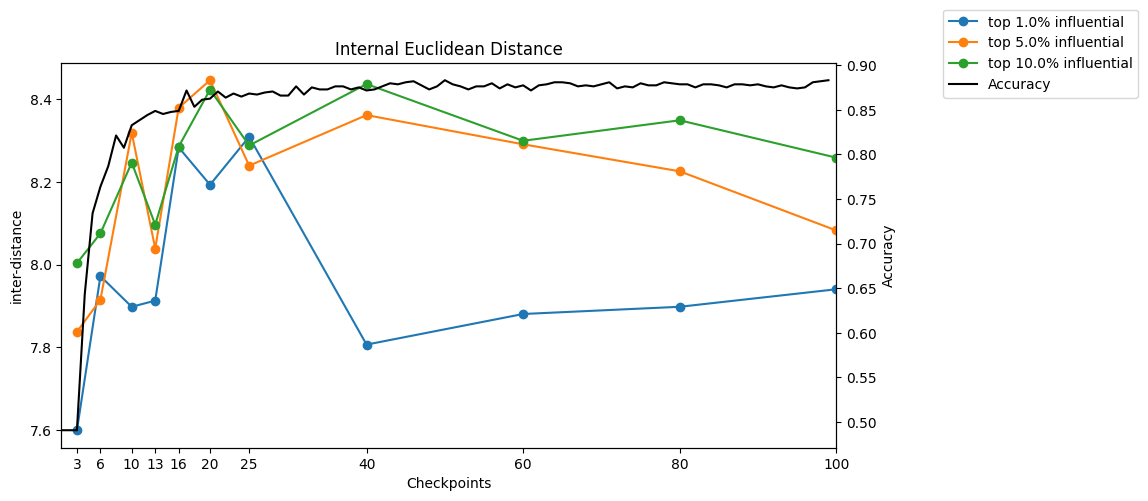

In [16]:
ls_p = [0.01, 0.05, 0.1]

for k in range(len(scoring_methods)):
    ls_int_distances = calc_pairwise_euclideans(influences_methods[k], sst2_embed_train_subset, list_p=ls_p, option="textcnn")
    kwargs = {
        "title": "Internal Euclidean Distance",
        "y_label": "inter-distance",
        "data": ls_int_distances,
        "legend_labels": [f"top {prob*100}% influential" for prob in ls_p]
    }
    plot_var_acc_legends(x_vals, checkpoint_labels, accuracies, **kwargs)

In [17]:
ckpt_embeds = embeds_dict[scoring_methods[i]]["random"]
tmp = np.array([embed[0] for embed in ckpt_embeds[i]])[:, 0, :]
tmp.shape

(250, 768)

In [18]:
ckpt_embeds = embeds_dict[scoring_methods[i]]["top"]
tmp = np.array([embed[0] for embed in ckpt_embeds[i]])[:, 0, :]
tmp.shape

(250, 768)

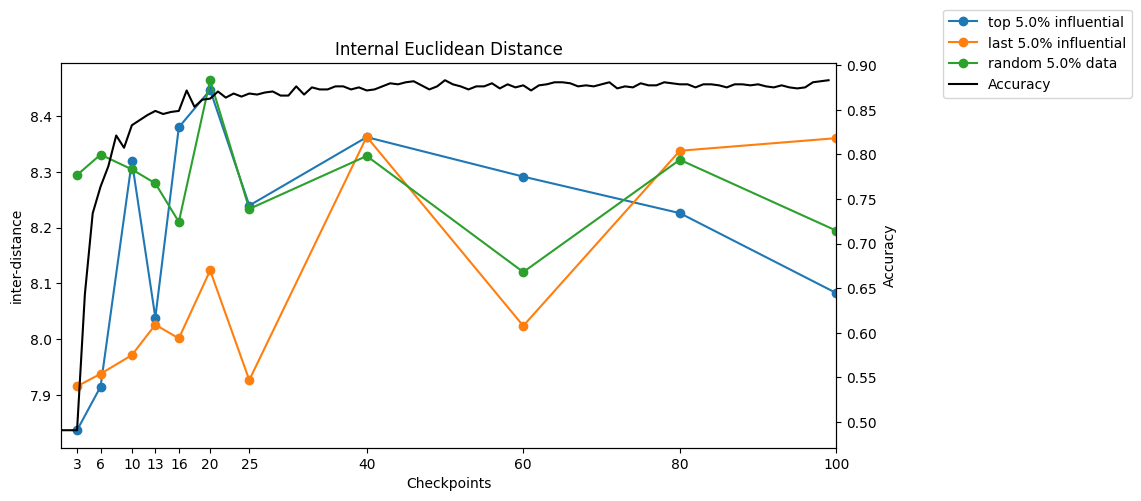

In [ ]:
p = 0.05
for i in range(len(scoring_methods)):
    topinf_int_distances = create_inf_int_distances(embeds_dict[scoring_methods[i]]["top"], option="textcnn")
    lastinf_int_distances = create_inf_int_distances(embeds_dict[scoring_methods[i]]["last"], option="textcnn")
    rand_int_distances = create_inf_int_distances(embeds_dict[scoring_methods[i]]["random"], option="textcnn")

    kwargs = {
        "title": "Internal Euclidean Distance",
        "y_label": "inter-distance",
        "data": [topinf_int_distances, rand_int_distances],
        "legend_labels": [f"top {p*100}% influential", f"random {p*100}% data"]
    }
    plot_var_acc_legends(x_vals, checkpoint_labels, accuracies, **kwargs)

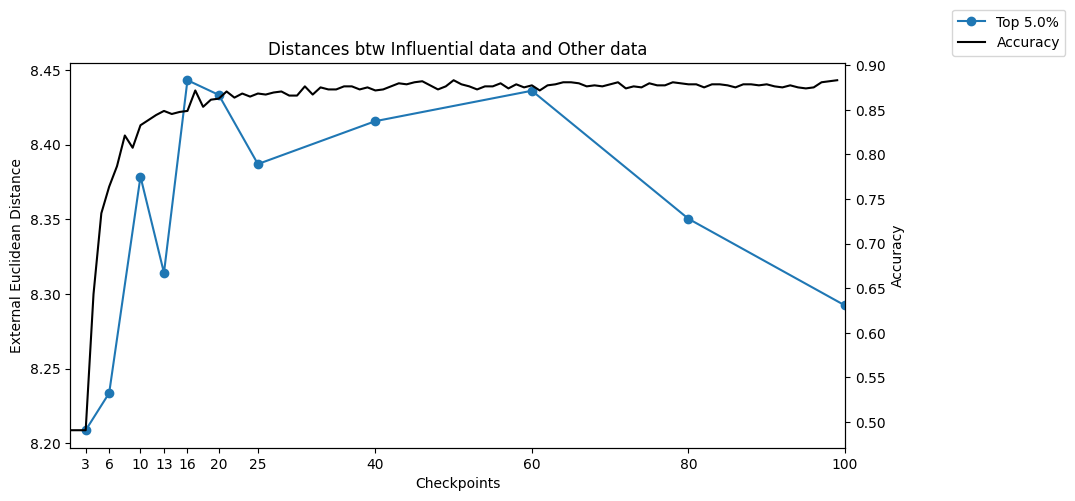

In [20]:
# Euclidean distance from influential points to other points
for i in range(len(scoring_methods)):
    distances = calc_dist_inf_to_others(select_inf_embeds = embeds_dict[scoring_methods[i]]["top"], 
                                        other_inf_embeds = embeds_dict[scoring_methods[i]]["random_large"], option="textcnn")

    kwargs = {
        "title": "Distances btw Influential data and Other data",
        "y_label": "External Euclidean Distance",
        "data": [distances],
        "legend_labels": [f"Top {p*100}%"]
    }
    plot_var_acc_legends(x_vals, checkpoint_labels, accuracies, **kwargs)


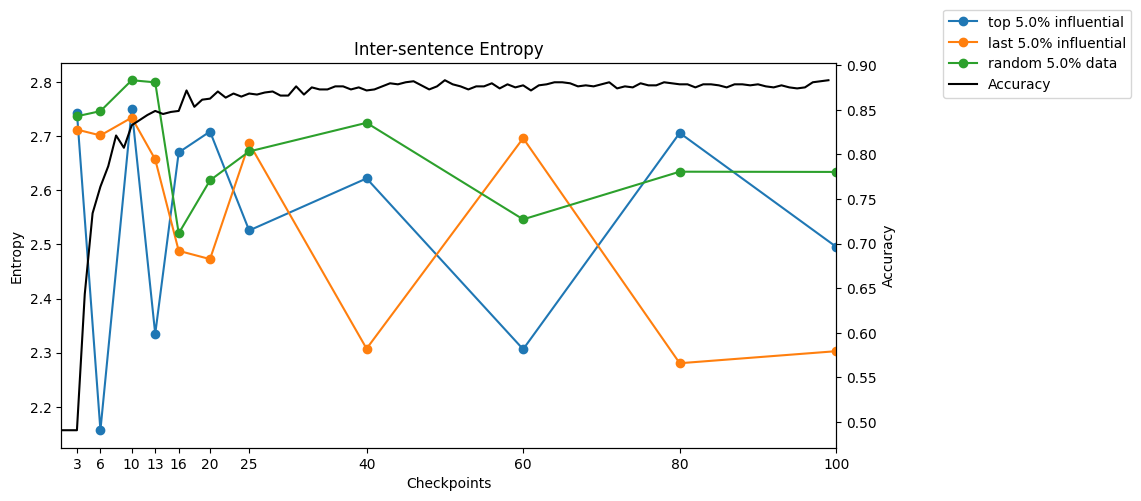

In [21]:
for i in range(len(scoring_methods)):
    topinf_entropies = create_inter_entropies(embeds_dict[scoring_methods[i]]["top"], option="textcnn")
    lastinf_pw_entropies = create_inter_entropies(embeds_dict[scoring_methods[i]]["last"], option="textcnn")
    rand_pw_entropies = create_inter_entropies(embeds_dict[scoring_methods[i]]["random"], option="textcnn")
    
    kwargs = {
        "title": "Inter-sentence Entropy",
        "y_label": "Entropy",
        "data": [topinf_entropies, lastinf_pw_entropies, rand_pw_entropies],
        "legend_labels": [f"top {p*100}% influential", f"last {p*100}% influential", f"random {p*100}% data"]
    }
    plot_var_acc_legends(x_vals, checkpoint_labels, accuracies, **kwargs)

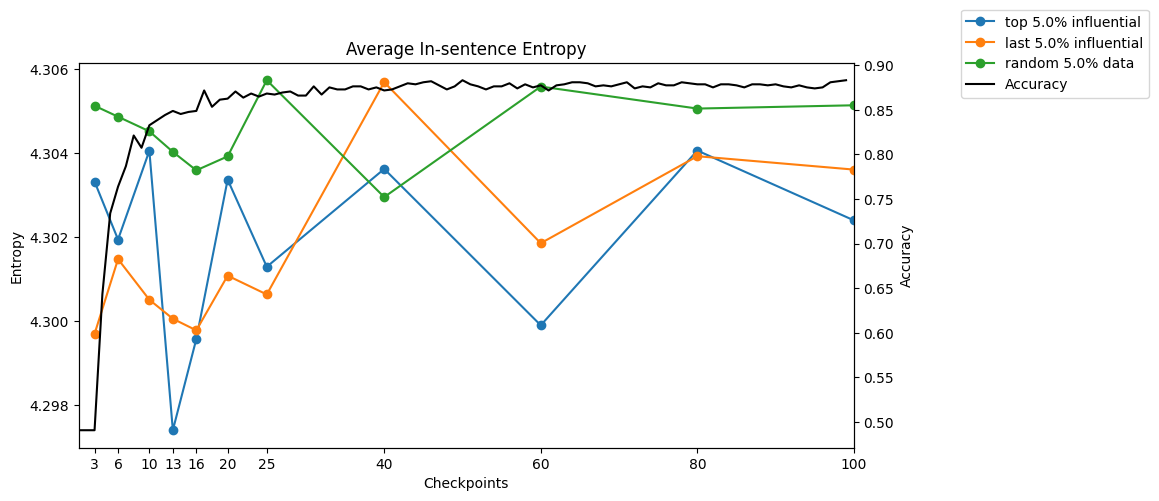

In [22]:
for i in range(len(scoring_methods)):
    topinf_entropies = create_inner_entropies(embeds_dict[scoring_methods[i]]["top"])
    lastinf_pw_entropies = create_inner_entropies(embeds_dict[scoring_methods[i]]["last"])
    rand_pw_entropies = create_inner_entropies(embeds_dict[scoring_methods[i]]["random"])

    kwargs = {
        "title": "Average In-sentence Entropy",
        "y_label": "Entropy",
        "data": [topinf_entropies, lastinf_pw_entropies, rand_pw_entropies],
        "legend_labels": [f"top {p*100}% influential", f"last {p*100}% influential", f"random {p*100}% data"]
    }
    plot_var_acc_legends(x_vals, checkpoint_labels, accuracies, **kwargs)

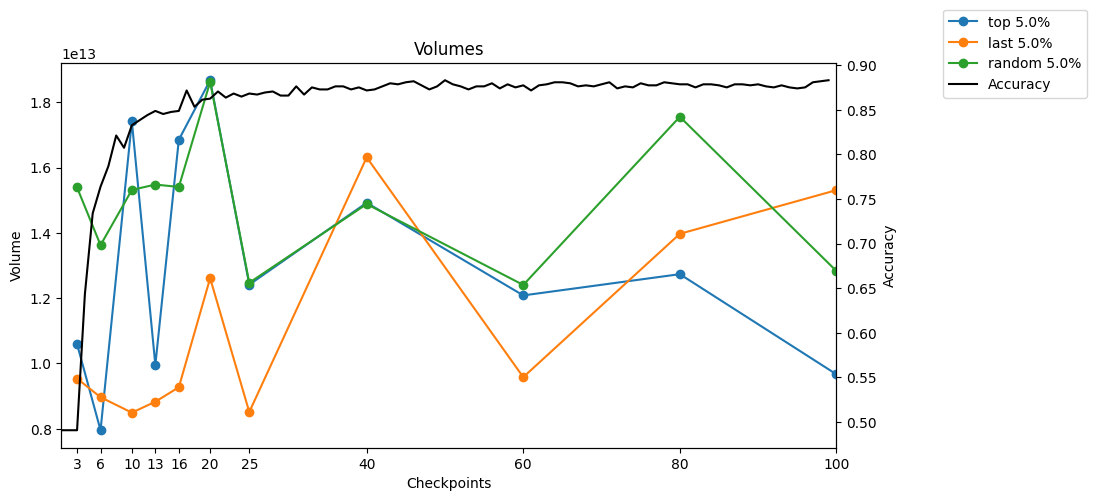

In [ ]:
labels = ["top", "random"]

for i in range(len(scoring_methods)):
    ls_volumes = calc_volumes([embeds_dict[scoring_methods[i]]["top"], embeds_dict[scoring_methods[i]]["random"]], option="textcnn")
    kwargs = {
        "title": "Volumes",
        "y_label": "Volume",
        "data": ls_volumes,
        "legend_labels": [f"{label} {p*100}%" for label in labels]
    }
    plot_var_acc_legends(x_vals, checkpoint_labels, accuracies, **kwargs)

# Retrain on Top n IP

In [24]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Device: ", device)

Device:  cuda


In [25]:
class TextCNN(nn.Module):
    def __init__(self, embed_dim=768, num_classes=2, kernel_sizes=[2, 3, 4], num_filters=2):
        super(TextCNN, self).__init__()
        self.convs = nn.ModuleList([
            nn.Conv2d(1, num_filters, (k, embed_dim)) for k in kernel_sizes
        ])
        self.dropout = nn.Dropout(0.5)
        self.fc = nn.Linear(len(kernel_sizes) * num_filters, num_classes)
        
    def forward(self, x):
        conv_outputs = []
        for conv in self.convs:
            conv_output = F.relu(conv(x)) # [batch size, num_filters, seq_len - kernel_size + 1, 1]
            conv_output_pool = F.max_pool2d(conv_output, (conv_output.shape[2], 1))
            conv_outputs.append(conv_output_pool.squeeze(3).squeeze(2))
        output = torch.cat(conv_outputs, dim=1)
        output = self.dropout(output)
        output = self.fc(output)
        return output

    def to(self, device):
        super().to(device)
        self.device = device
        return self

In [26]:
def plot_get_losses(ls_embeds, legend_labels, losses):
    fig, ax1 = plt.subplots(figsize=(10, 5))
    ax1.set_xlim(min(x_vals), max(x_vals))
    for j, ckpts_embeds in enumerate(ls_embeds):
        train_losses = [] # CrossEntropy loss
        for i, embeds in enumerate(ckpts_embeds):
            checkpoint = checkpoints_filepaths[i]
            inputs = torch.tensor(np.array([embed[0] for embed in embeds]), dtype=torch.float32, device=device).unsqueeze(1)
            expect_val = torch.tensor([embed[1] for embed in embeds], device=device)
            optimizer = torch.optim.Adam(TextCNN().parameters(), lr=0.0001)
            model, optimizer, _, _ = load_checkpoint(TextCNN().to(device), optimizer, checkpoint)
            loss_fn = nn.CrossEntropyLoss()
            outputs = model(inputs)
            loss = loss_fn(outputs, expect_val)
            train_losses.append(loss.item())
        ax1.plot(checkpoint_labels, train_losses, 'o-', 
                label=f"{legend_labels[j]} {p*100}% train loss")

    plt.title("Train loss (CE)")
    ax1.set_xlabel("Checkpoint")
    ax1.set_ylabel("Loss")
    ax1.set_xticks(checkpoint_labels)
    ax1.plot(losses, label="train loss", color='k')

    fig.legend(loc='upper left', bbox_to_anchor=(1,1))
    plt.show()

def plot_get_accs(ls_embeds, legend_labels, train_accuracies):
    fig, ax1 = plt.subplots(figsize=(10, 5))
    ax1.set_xlim(min(x_vals), max(x_vals))

    for j, ckpts_embeds in enumerate(ls_embeds):
        accuracies = []
        
        for i, embeds in enumerate(ckpts_embeds):
            checkpoint = checkpoints_filepaths[i]
            inputs = torch.tensor(np.array([embed[0] for embed in embeds]), dtype=torch.float32, device=device).unsqueeze(1)
            expect_val = torch.tensor([embed[1] for embed in embeds], device=device)
            optimizer = torch.optim.Adam(TextCNN().parameters(), lr=0.0001)
            model, optimizer, _, _ = load_checkpoint(TextCNN().to(device), optimizer, checkpoint)
            outputs = model(inputs)
            predictions = torch.argmax(outputs, dim=-1)
            accuracy = (predictions == expect_val).sum() / len(expect_val)
            accuracies.append(accuracy.cpu())
        ax1.plot(checkpoint_labels, accuracies, 'o-', 
                label=f"{legend_labels[j]} {p*100}% accuracy")

    plt.title("Training data accuracy")
    ax1.set_xlabel("Checkpoint")
    ax1.set_ylabel("Accuracy")
    ax1.set_xticks(checkpoint_labels)
    ax1.plot(train_accuracies, label="Accuracy", color='k')

    fig.legend(loc='upper left', bbox_to_anchor=(1,1))
    plt.show()

## For IF

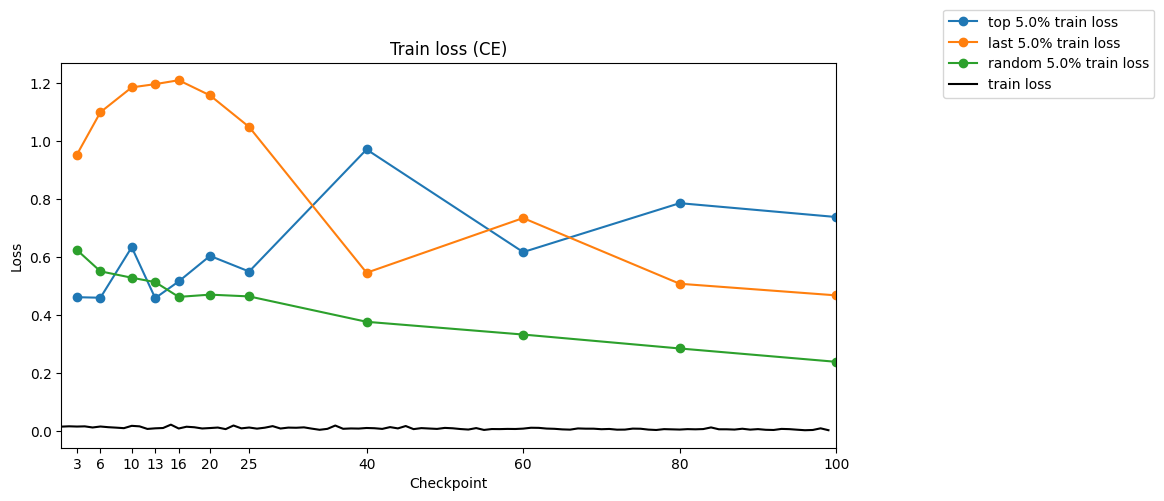

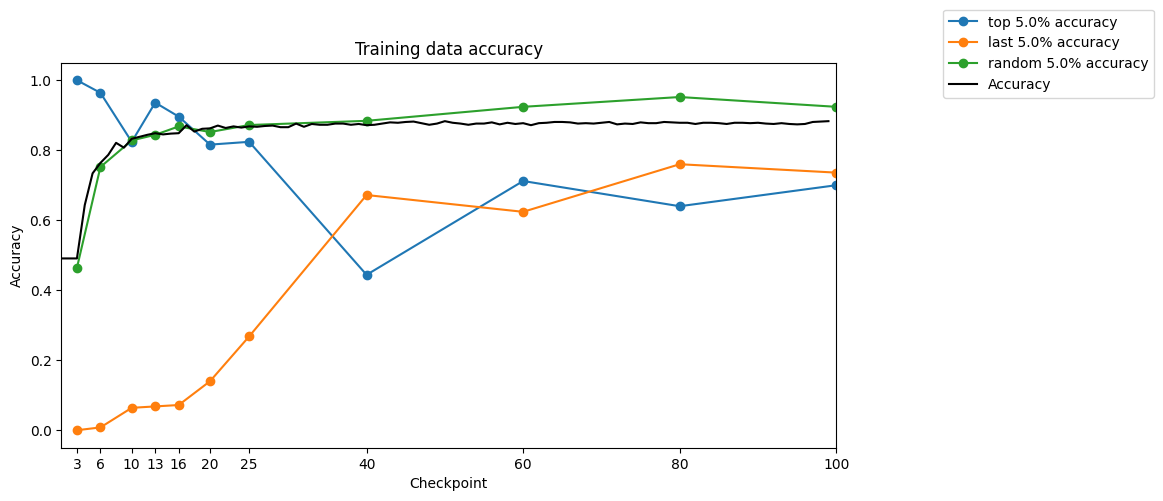

In [27]:
labels = ["top", "last", "random"]
ls_embeds = [embeds_dict["if"]["top"],
             embeds_dict["if"]["last"],
             embeds_dict["if"]["random"]]
plot_get_losses(ls_embeds, labels, train_losses)
plot_get_accs(ls_embeds, labels, accuracies)

## For TracIn

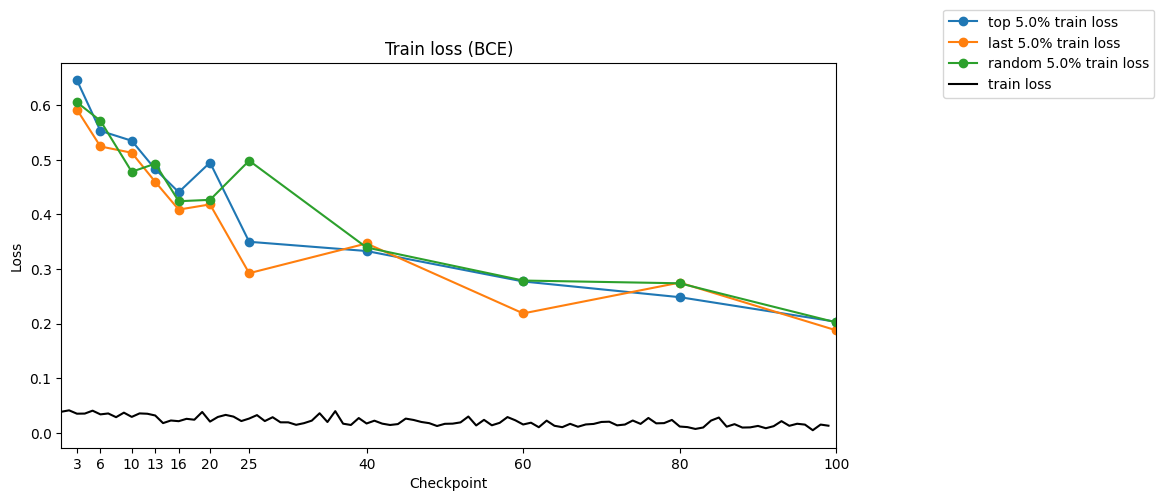

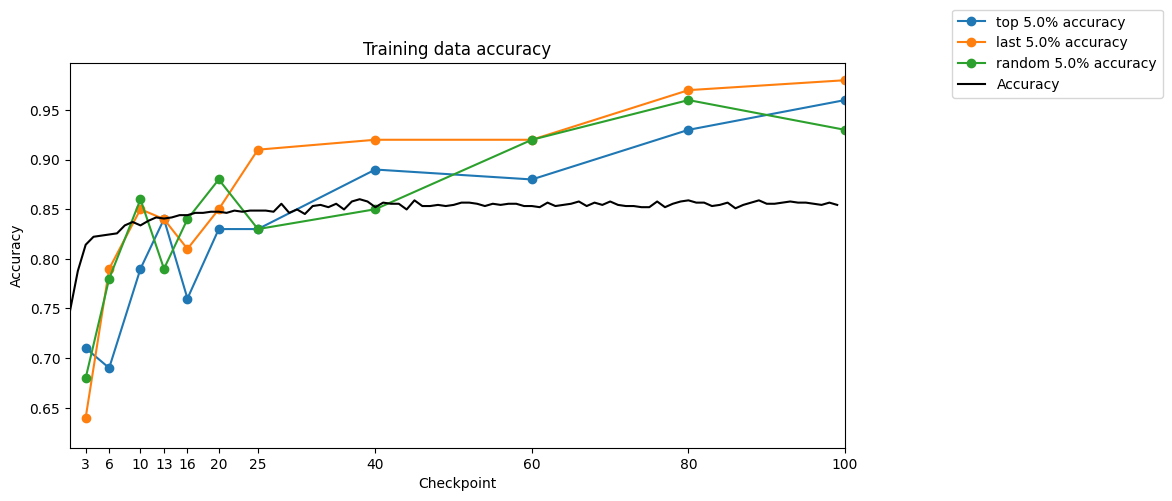

In [42]:
labels = ["top", "last", "random"]
ls_embeds = [embeds_dict["tracin"]["top"],
             embeds_dict["tracin"]["last"],
             embeds_dict["tracin"]["random"]]
plot_get_losses(ls_embeds, labels, train_losses)
plot_get_accs(ls_embeds, labels, accuracies)

# Similar Indexes

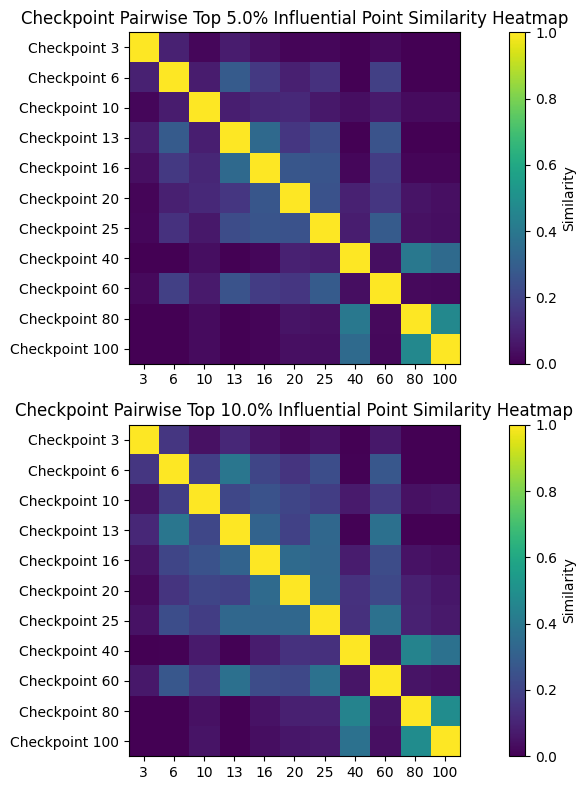

In [28]:
for i in range(len(scoring_methods)):
    pw_similarities_lowp = pairwise_similarity(top_inf_indices(influences_methods[i], int(p*num_data)))
    pw_similarities_highp = pairwise_similarity(top_inf_indices(influences_methods[i], int(0.1*num_data)))

    plot_similar_indices(pw_similarities_lowp, pw_similarities_highp, checkpoint_labels, p)

# Decision boundary

In [ ]:
import matplotlib.colors as mcolors

In [ ]:
optimizer = torch.optim.Adam(TextCNN().parameters(), lr=0.0001)
for i in range(len(scoring_methods)):
    dist_lst = []
    for j, ckpts_embeds in enumerate([embeds_dict[scoring_methods[i]]["top"], embeds_dict[scoring_methods[i]]["last"], embeds_dict[scoring_methods[i]]["random"]]):
        distance_to_dec_boundary = []
        
        for k, embeds in enumerate(ckpts_embeds):
            checkpoint = checkpoints_filepaths[k]
            inputs = torch.tensor(np.array([embed[0] for embed in embeds]), dtype=torch.float32, device=device)
            model, optimizer, _, _ = load_checkpoint(TextCNN().to(device), optimizer, checkpoint)
            outputs = model(inputs)
            top_logits = torch.sort(outputs, descending=True, dim=-1).values
            distances = torch.mean(top_logits[:, 0] - top_logits[:, 1])
            distance_to_dec_boundary.append(distances.item())
        dist_lst.append(distance_to_dec_boundary)
    kwargs = {
        "title": f"{scoring_methods[i]}: Distances to Decision Boundary",
        "y_label": "Distance",
        "data": dist_lst,
        "legend_labels": [f"{label} {p*100}%" for label in labels]
    }
    plot_var_acc_legends(x_vals, checkpoint_labels, accuracies, **kwargs)

Plotting Decision Boundary: 100%|██████████| 11/11 [00:02<00:00,  5.45it/s]


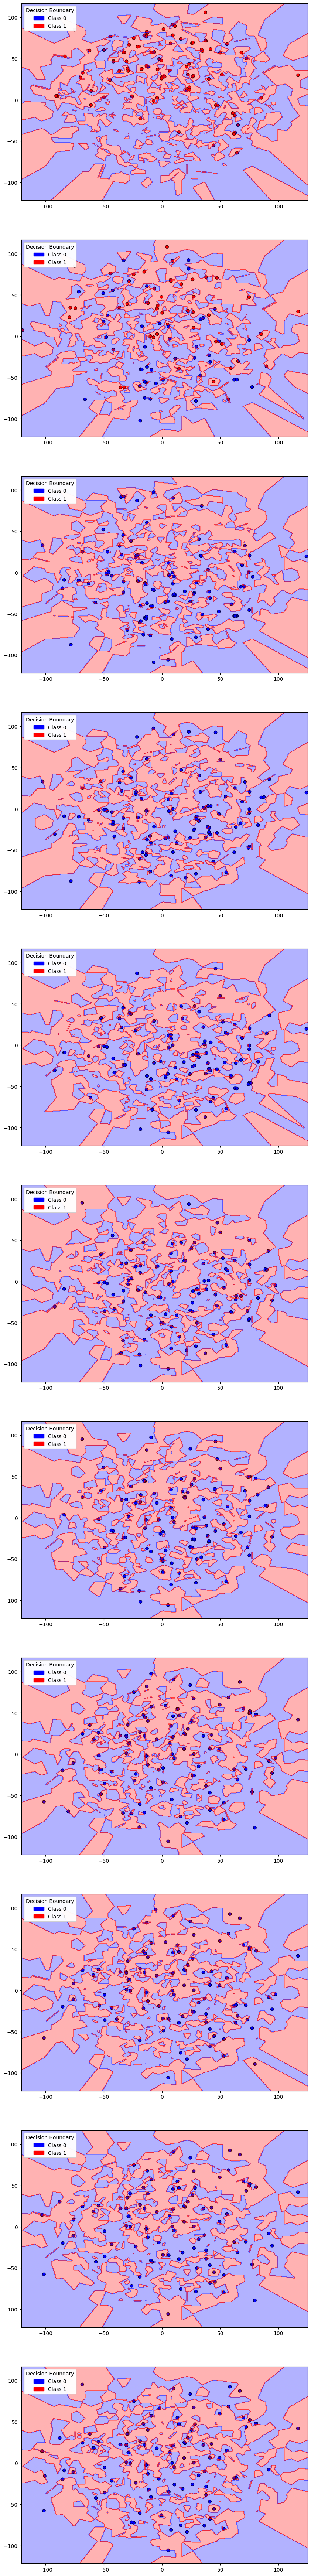

In [ ]:
ckpts_top_inf_indices = top_inf_indices(sst2_influences_if, int(p*num_data))
for i in range(len(scoring_methods)):
    all_x_2d, all_data_y, all_data_x = tsne_all_dataset(sst2_embed_train_subset)
    fig, ax = plt.subplots(len(checkpoint_labels), 1, figsize=(10, 90))
    custom_cmap = mcolors.ListedColormap(["blue", "red"])
    norm = mcolors.Normalize(0, 1)
    for i, ckpt_top_inf_indices in tqdm(enumerate(ckpts_top_inf_indices), desc='Plotting Decision Boundary', total=len(checkpoint_labels)):
        model, _, _, _ = load_checkpoint(TextCNN().to(device), torch.optim.Adam(TextCNN().parameters(), lr=0.0001), checkpoints_filepaths[i])
        output = model(torch.tensor(all_data_x, dtype=torch.float32, device=device))
        all_y_pred = torch.argmax(output, dim=-1).flatten() # should be (N,)
        plt_decision_boundary(ckpt_top_inf_indices, checkpoint_labels, all_x_2d, all_data_y, all_y_pred, ax[i], i, custom_cmap, norm)
    # fig.tight_layout()
    plt.show()